# Visualização e Interpretação de Dados

**Aluna:** Layse Steffany Pereira de Souza · UDF · Sistemas de Informação · Ciência de Dados e Aprendizado de Máquina (2026/2)

**Aula:** 02/09 · Unidade II – Análise e Ciência de Dados
**Atividade:** criar gráficos e interpretar informações obtidas dos dados.
**Entregável:** conjunto de visualizações comentadas (as figuras ficam salvas em `figuras/`).

Cada gráfico é seguido de um comentário: **o que mostra → o que significa → que decisão apoia**.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta do notebook.
# No Google Colab, antes de rodar:
#   !git clone https://github.com/LaySteff/ciencia_dados_aprendizado_maquina.git
#   %cd ciencia_dados_aprendizado_maquina/unidade2_analise_e_ciencia_de_dados
RAIZ = Path.cwd().resolve().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

if config.usando_dados_sinteticos():
    print("AVISO: usando a base SINTÉTICA de demonstração. "
          "Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.")
else:
    print("Usando a amostra real do EMBER.")

AVISO: usando a base SINTÉTICA de demonstração. Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.


In [2]:
from src.preparacao import carregar_tratado

df = carregar_tratado()
df["classe"] = df["label"].map({0: "seguro", 1: "malicioso"})
df.shape

(5700, 20)

## V1. Equilíbrio entre as classes

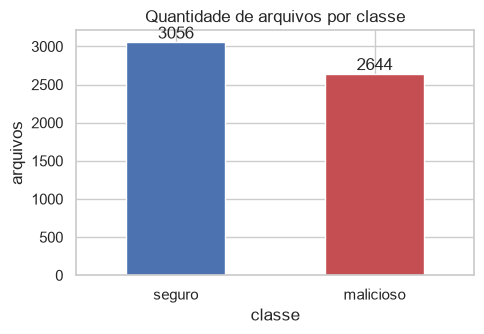

classe
seguro       53.6
malicioso    46.4
Name: proportion, dtype: float64

In [3]:
ax = df["classe"].value_counts().plot.bar(rot=0, figsize=(5, 3.5), color=["#4C72B0", "#C44E52"])
ax.bar_label(ax.containers[0]); ax.set_title("Quantidade de arquivos por classe"); ax.set_ylabel("arquivos")
plt.tight_layout(); plt.savefig(FIGURAS / "v1_classes.png", dpi=120); plt.show()
(df["classe"].value_counts(normalize=True) * 100).round(1)

> ⚠️ Valores obtidos com a base **sintética** de demonstração. Refaça a interpretação após rodar com a amostra real do EMBER.

**O que mostra:** 53,6% seguros e 46,4% maliciosos. **Significado:** as classes estão quase equilibradas, então a acurácia não engana muito. Mesmo assim vamos olhar precisão, recall e F1. **Decisão:** não é preciso reamostrar a base.

## V2. Entropia das seções por classe (hipótese H1)

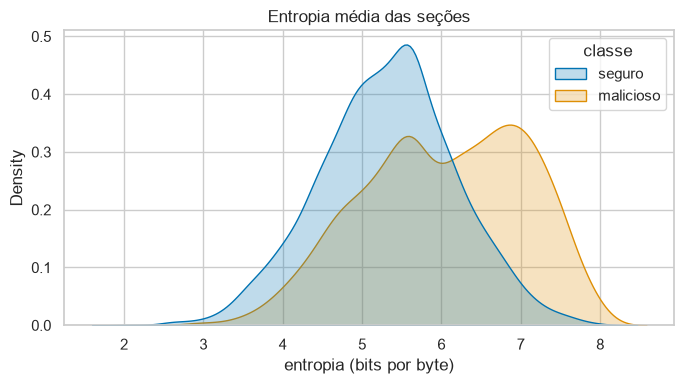

,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
malicioso,2644.0,6.04,1.02,2.81,5.29,6.11,6.88,7.95
seguro,3056.0,5.32,0.86,2.11,4.76,5.34,5.88,7.95


In [4]:
plt.figure(figsize=(7, 4))
sns.kdeplot(data=df, x="entropia_media_secao", hue="classe", fill=True, common_norm=False)
plt.title("Entropia média das seções"); plt.xlabel("entropia (bits por byte)")
plt.tight_layout(); plt.savefig(FIGURAS / "v2_entropia.png", dpi=120); plt.show()
df.groupby("classe")["entropia_media_secao"].describe().round(2)

**O que mostra:** a curva dos maliciosos está deslocada para a direita e tem uma "cauda" perto de 7–8 bits/byte. **Significado:** parte dos malwares é compactada ou cifrada (entropia perto do máximo), mas muitos têm entropia parecida com a dos arquivos seguros. **Decisão:** entropia alta é um bom **sinal de alerta**, mas não basta para bloquear um arquivo sozinha.

## V3. Indicadores binários

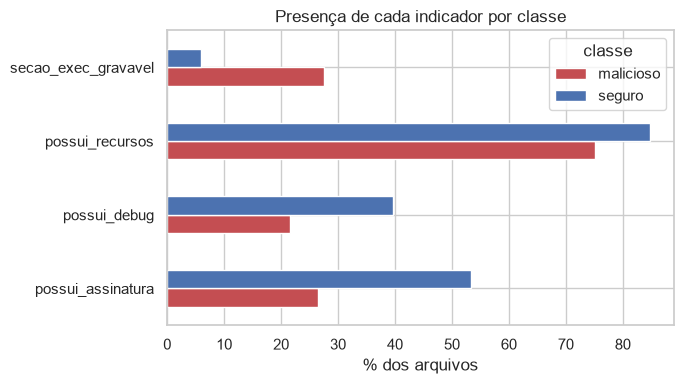

classe,malicioso,seguro
possui_assinatura,26.6,53.3
possui_debug,21.5,39.7
possui_recursos,75.1,84.8
secao_exec_gravavel,27.5,5.9


In [5]:
taxa = df.groupby("classe")[config.COLUNAS_BOOLEANAS].mean().T * 100
ax = taxa.plot.barh(figsize=(7, 4), color={"seguro": "#4C72B0", "malicioso": "#C44E52"})
ax.set_xlabel("% dos arquivos"); ax.set_title("Presença de cada indicador por classe")
plt.tight_layout(); plt.savefig(FIGURAS / "v3_binarios.png", dpi=120); plt.show()
taxa.round(1)

**O que mostra:** só 27% dos maliciosos têm assinatura digital, contra 53% dos seguros. Seções ao mesmo tempo executáveis e graváveis aparecem em 27% dos maliciosos e em só 6% dos seguros. **Significado:** a falta de assinatura e as seções executável+gravável (típicas de código que se modifica) aumentam o risco. **Decisão:** a triagem pode dar prioridade a arquivos sem assinatura e com seção executável+gravável.

## V4. Importações e tamanho

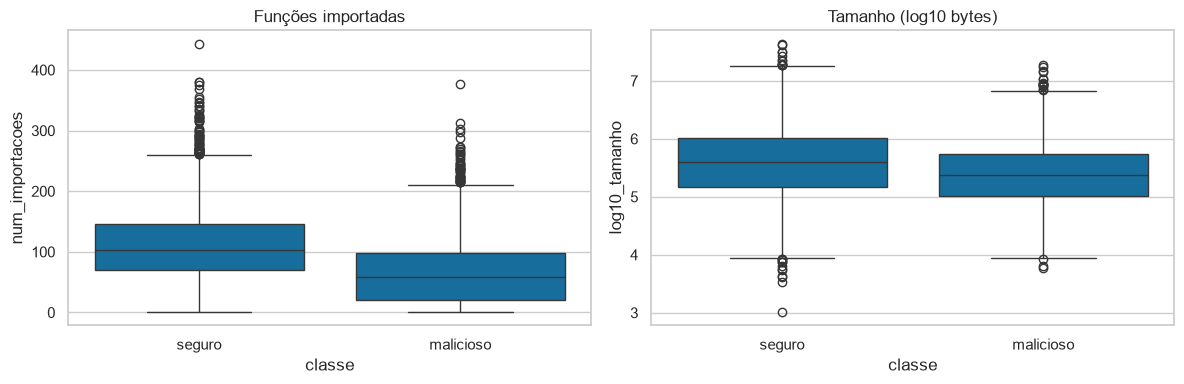

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="classe", y="num_importacoes", ax=axes[0]); axes[0].set_title("Funções importadas")
sns.boxplot(data=df, x="classe", y="log10_tamanho", ax=axes[1]); axes[1].set_title("Tamanho (log10 bytes)")
plt.tight_layout(); plt.savefig(FIGURAS / "v4_importacoes_tamanho.png", dpi=120); plt.show()

**O que mostra:** os maliciosos importam menos funções e tendem a ser menores, mas as caixas se sobrepõem bastante. **Significado:** são diferenças de tendência, não regras. **Decisão:** usar estas variáveis junto com as outras no modelo, e não como filtro isolado.

## V5. Evolução no tempo

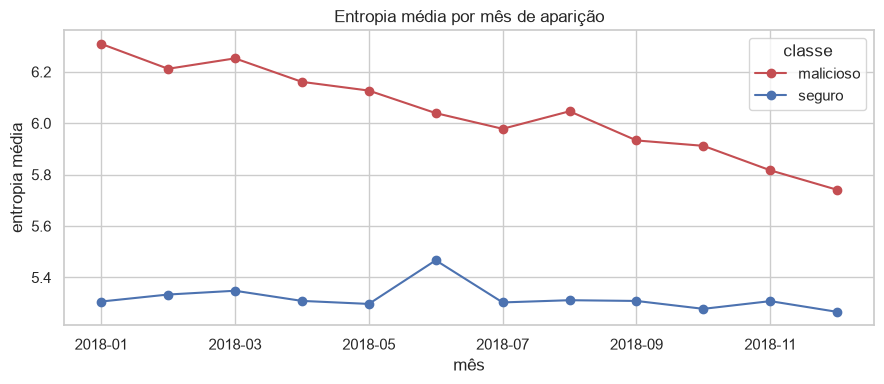

mes_aparicao,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10,2018-11,2018-12
classe,,,,,,,,,,,,
malicioso,6.31,6.21,6.25,6.16,6.13,6.04,5.98,6.05,5.93,5.91,5.82,5.74
seguro,5.31,5.33,5.35,5.31,5.30,5.47,5.30,5.31,5.31,5.28,5.31,5.27


In [7]:
mensal = df.groupby(["mes_aparicao", "classe"])["entropia_media_secao"].mean().unstack()
ax = mensal.plot(marker="o", figsize=(9, 4), color={"seguro": "#4C72B0", "malicioso": "#C44E52"})
ax.set_title("Entropia média por mês de aparição"); ax.set_ylabel("entropia média"); ax.set_xlabel("mês")
plt.tight_layout(); plt.savefig(FIGURAS / "v5_temporal.png", dpi=120); plt.show()
mensal.round(2).T

**O que mostra:** a entropia média dos maliciosos cai ao longo do ano (≈ 6,3 em janeiro, ≈ 5,7 em dezembro), enquanto a dos seguros fica estável. **Significado:** os malwares recentes ficam mais parecidos com software legítimo (**deriva de conceito**). **Decisão:** é preciso retreinar o modelo periodicamente e testá-lo em dados mais novos (hipótese H3).

## V6. Correlação entre variáveis

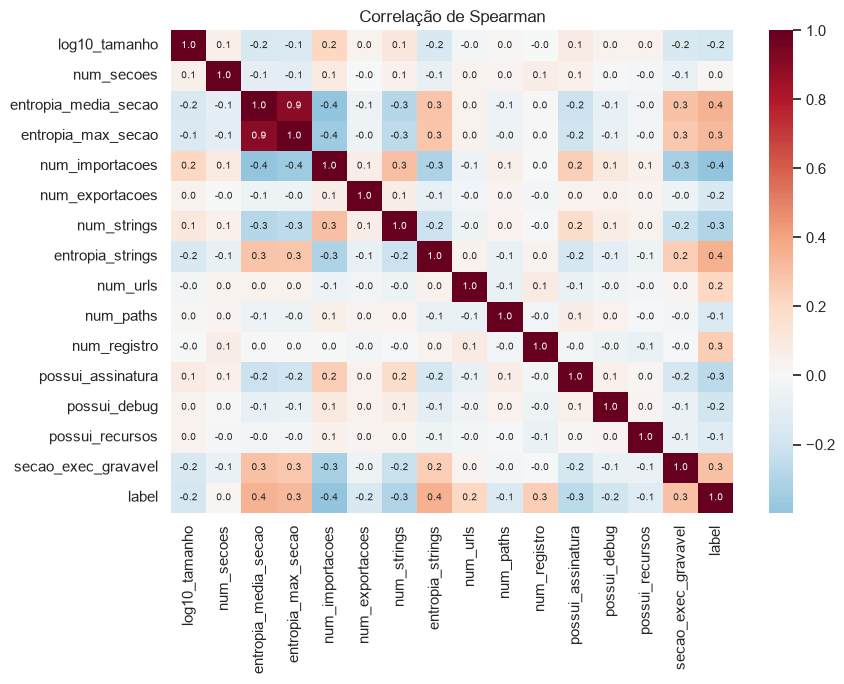

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[config.FEATURES + ["label"]].corr(method="spearman"), cmap="RdBu_r", center=0,
            annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlação de Spearman"); plt.tight_layout()
plt.savefig(FIGURAS / "v6_correlacao.png", dpi=120); plt.show()

**O que mostra:** as entropias são correlacionadas entre si, e importações e strings andam juntas (negativamente ligadas ao rótulo). **Significado:** há informação repetida entre as variáveis. Isso não atrapalha os modelos de árvore, mas deixa os coeficientes da regressão logística mais difíceis de interpretar. **Decisão:** manter as variáveis e interpretar a importância delas em conjunto.